# 📘 6.4 Gaussian Quadrature

### Choosing evaluation locations to obtain more information per sample

Newton–Cotes methods begin with prescribed, usually equally spaced nodes and
choose weights for those nodes. **Gaussian quadrature** makes a different design
choice: it selects both the nodes and the weights to integrate a broad class of
functions efficiently.

This notebook focuses on **Gauss–Legendre quadrature**, the standard Gaussian rule
for finite intervals with no additional weighting function. We will visualise its
nodes, map them onto engineering coordinates and use them to calculate nonlinear
spring work and rocket-motor impulse.


## Before you begin: what is being chosen?

The equations in this notebook describe a weighted sum. The central idea is more
important than memorising a table of numbers:

> If we are free to choose where a model is evaluated, some locations provide
> more integration accuracy than equally spaced locations.

We continue to use $I$ for the ideal integral. We introduce $G_n$ for an
$n$-point Gauss–Legendre approximation. The subscript $n$ is the number of
function evaluations; it is not a new version of $I$:

$$G_n\approx I.$$

Every node and weight will be defined before it is used. Pay particular attention
to the distinction between:

* the standard coordinate $\xi$ on $[-1,1]$;
* the physical coordinate $x$ on $[a,b]$; and
* the scale factor required when moving between those intervals.

Gaussian quadrature is useful when a callable equation, simulation or surrogate
model can be evaluated at selected locations. It is generally not the first
choice when only fixed, irregular experimental samples are available, because the
required Gaussian-node values were never measured.


### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* explain how Gaussian and Newton–Cotes quadrature choose nodes differently;
* define Gauss–Legendre nodes, weights and quadrature order;
* apply a Gauss–Legendre weighted sum on $[-1,1]$;
* transform nodes and weights to a physical interval $[a,b]$;
* explain the polynomial exactness degree $2n-1$;
* use `numpy.polynomial.legendre.leggauss` and `scipy.integrate.fixed_quad`;
* compare accuracy per function evaluation;
* recognise when composite panels improve a localised problem; and
* identify limitations involving fixed samples, non-smoothness and data quality.

### 🔗 Unit Learning Outcome Alignment

This notebook supports:

* **LO1:** Assess the suitability and limitations of numerical analysis tools.
* **LO2:** Develop defensible solutions to open-ended engineering problems.
* **LO3:** Evaluate numerical performance, error, stability and accuracy.

### 📚 Sources used in this notebook

* NIST DLMF — [Gauss quadrature](https://dlmf.nist.gov/3.5#v)
* SciPy — [`integrate.fixed_quad`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.fixed_quad.html)
* NumPy — [`polynomial.legendre.leggauss`](https://numpy.org/doc/stable/reference/generated/numpy.polynomial.legendre.leggauss.html)
* SciPy — [`special.roots_legendre`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.roots_legendre.html)


## 📂 6.4.0 How to use this notebook

This is a **pre-work content notebook**. Run every cell from top to bottom; no
cell requires editing or typed input. All teaching examples are deterministic and
self-contained.

Notebook 6.4 treats one-dimensional finite-interval integrals. Notebook 6.5 will
extend numerical integration to multiple dimensions.


### 📖 Core language for 6.4

* A **quadrature node** is a coordinate where the integrand is evaluated.
* A **quadrature weight** multiplies the value at one node in the weighted sum.
* The **quadrature order** $n$ is the number of Gaussian nodes and weights.
* **Gauss–Legendre quadrature** uses roots of the Legendre polynomial $P_n(\xi)$
  as nodes on $[-1,1]$.
* An $n$-point Gauss–Legendre rule has polynomial degree of exactness $2n-1$.
* A **coordinate transformation** maps standard nodes $\xi_i$ to physical nodes
  $x_i$ on $[a,b]$.
* **Fixed-order** means that $n$ is selected before the calculation; the method
  does not adaptively add nodes by itself.
* **Composite Gaussian quadrature** applies a Gaussian rule separately on several
  subintervals.


In [ ]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from numpy.polynomial.legendre import leggauss
from scipy.integrate import fixed_quad, quad, simpson, trapezoid
from scipy.special import eval_legendre

pd.set_option("display.precision", 10)
plt.rcParams["figure.figsize"] = (8.5, 5.0)


## 📂 6.4.1 A weighted sum on the standard interval

Consider the ideal integral

$$
I=\int_{-1}^{1}f(\xi)\,\mathrm{d}\xi.
$$

Here $\xi$ is the coordinate on the standard interval $[-1,1]$. An $n$-point
Gauss–Legendre approximation is

$$
G_n=\sum_{i=1}^{n}w_i f(\xi_i).
$$

The notation means:

* $G_n$: the Gaussian approximation formed from $n$ evaluations;
* $i$: the node index, running from 1 to $n$;
* $\xi_i$: the location of node $i$ on $[-1,1]$;
* $w_i$: the positive weight assigned to node $i$; and
* $f(\xi_i)$: the integrand evaluated at that node.

The approximation is a weighted sum, not an integral evaluated exactly in
general. Its power comes from the carefully selected pairs $(\xi_i,w_i)$.


## 📂 6.4.2 The two-point rule

The two-point Gauss–Legendre rule uses

$$
\xi_1=-\frac{1}{\sqrt{3}},\qquad
\xi_2=\frac{1}{\sqrt{3}},
$$

with

$$w_1=w_2=1.$$

Therefore

$$
G_2=f\!\left(-\frac{1}{\sqrt{3}}\right)
+f\!\left(\frac{1}{\sqrt{3}}\right).
$$

These interior nodes are not arbitrary. They are the roots of the second Legendre
polynomial $P_2(\xi)$. The associated weights ensure exact integration for every
polynomial up to degree 3.


In [ ]:
nodes_2, weights_2 = leggauss(2)

two_point_rule = pd.DataFrame(
    {
        "Node index i": [1, 2],
        "Standard node xi_i": nodes_2,
        "Weight w_i": weights_2,
    }
)
display(two_point_rule)
print(f"Sum of weights: {weights_2.sum():.10f}")


,Node index i,Standard node xi_i,Weight w_i
0,1,-0.5773502692,1.0
1,2,0.5773502692,1.0


Sum of weights: 2.0000000000


The weights sum to 2, which is the length of $[-1,1]$. This guarantees that the
rule integrates the constant function $f(\xi)=1$ correctly.


## 📂 6.4.3 Nodes are roots of a Legendre polynomial

The $n$ Gauss–Legendre nodes are the $n$ roots of $P_n(\xi)$. Legendre
polynomials are orthogonal on $[-1,1]$ with weight function 1. The orthogonality
theory explains why choosing these roots produces unusually high polynomial
exactness.

You are not expected to derive the roots by hand. The important connection is:

$$
P_n(\xi_i)=0
\quad\Longrightarrow\quad
\xi_i\text{ is a Gauss–Legendre node}.
$$

The code below shows $P_4$ and its four roots.


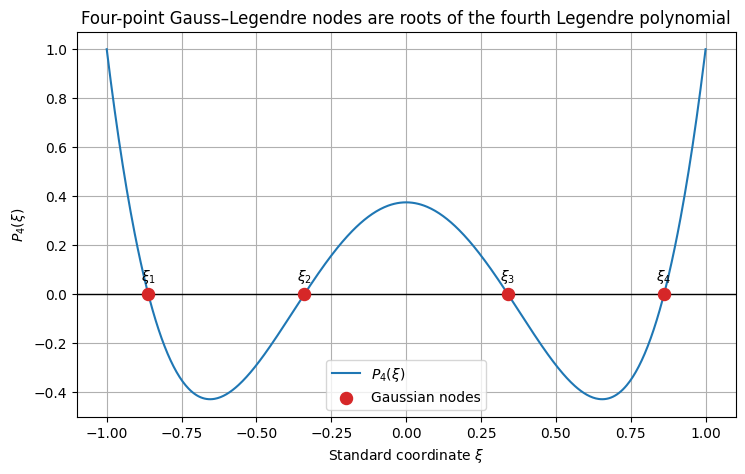

In [ ]:
order_4 = 4
nodes_4, weights_4 = leggauss(order_4)
xi_dense = np.linspace(-1.0, 1.0, 601)
polynomial_4 = eval_legendre(order_4, xi_dense)

fig, ax = plt.subplots()
ax.plot(xi_dense, polynomial_4, color="tab:blue", label=r"$P_4(\xi)$")
ax.axhline(0.0, color="black", linewidth=1)
ax.scatter(nodes_4, np.zeros_like(nodes_4), s=75, color="tab:red", zorder=3, label="Gaussian nodes")
for index, node in enumerate(nodes_4, start=1):
    ax.annotate(fr"$\xi_{index}$", (node, 0.0), xytext=(0, 10), textcoords="offset points", ha="center")
ax.set_xlabel(r"Standard coordinate $\xi$")
ax.set_ylabel(r"$P_4(\xi)$")
ax.set_title("Four-point Gauss–Legendre nodes are roots of the fourth Legendre polynomial")
ax.grid(True)
ax.legend()
plt.show()


## 📂 6.4.4 Polynomial exactness: why the nodes are valuable

An $n$-point Gauss–Legendre rule integrates every polynomial of degree up to

$$2n-1$$

exactly, apart from floating-point effects. For example:

| Gaussian points $n$ | Exact polynomial degree |
|---:|---:|
| 1 | 1 |
| 2 | 3 |
| 3 | 5 |
| 4 | 7 |
| 5 | 9 |

The rule has $2n$ design quantities—$n$ nodes and $n$ weights—which are chosen
to reproduce polynomial moments. Fixed-node Newton–Cotes rules do not have the
same freedom.


,Polynomial,Exact integral,Three-point Gaussian,Absolute error
0,xi^0,2.0000000000,2.0000000000,4.4408920985e-16
1,xi^1,0.0000000000,0.0000000000,0.0000000000e+00
2,xi^2,0.6666666667,0.6666666667,3.3306690739e-16
3,xi^3,0.0000000000,0.0000000000,0.0000000000e+00
4,xi^4,0.4000000000,0.4000000000,1.1102230246e-16
5,xi^5,0.0000000000,0.0000000000,0.0000000000e+00
6,xi^6,0.2857142857,0.2400000000,4.5714285714e-02
7,xi^7,0.0000000000,0.0000000000,0.0000000000e+00
8,xi^8,0.2222222222,0.1440000000,7.8222222222e-02
9,xi^9,0.0000000000,0.0000000000,0.0000000000e+00


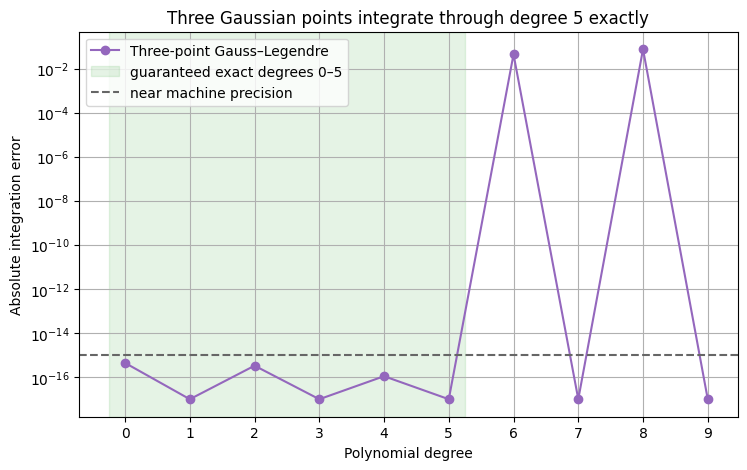

In [ ]:
gaussian_order = 3
nodes_3, weights_3 = leggauss(gaussian_order)
polynomial_degrees = np.arange(0, 10)

exact_values = np.array([
    0.0 if degree % 2 == 1 else 2.0 / (degree + 1)
    for degree in polynomial_degrees
])
gaussian_values = np.array([
    np.sum(weights_3 * nodes_3**degree)
    for degree in polynomial_degrees
])
polynomial_errors = np.abs(exact_values - gaussian_values)

exactness_table = pd.DataFrame(
    {
        "Polynomial": [f"xi^{degree}" for degree in polynomial_degrees],
        "Exact integral": exact_values,
        "Three-point Gaussian": gaussian_values,
        "Absolute error": polynomial_errors,
    }
)
display(exactness_table)

fig, ax = plt.subplots()
ax.semilogy(
    polynomial_degrees,
    np.maximum(polynomial_errors, 1e-17),
    "o-",
    color="tab:purple",
    label="Three-point Gauss–Legendre",
)
ax.axvspan(-0.25, 5.25, color="tab:green", alpha=0.12, label="guaranteed exact degrees 0–5")
ax.axhline(1e-15, color="0.4", linestyle="--", label="near machine precision")
ax.set_xlabel("Polynomial degree")
ax.set_ylabel("Absolute integration error")
ax.set_title("Three Gaussian points integrate through degree 5 exactly")
ax.set_xticks(polynomial_degrees)
ax.grid(True, which="both")
ax.legend()
plt.show()


Exactness through degree $2n-1$ is a precise polynomial result. It does not say
that every non-polynomial function is exact or that every engineering problem
needs only a few evaluations.

The higher odd powers in the table also show near-zero error. This does not extend
the general degree of exactness: an odd function integrates to zero over the
symmetric interval $[-1,1]$, and the symmetric Gaussian nodes cancel its paired
contributions. Degree $2n-1$ means the rule is exact for **every** polynomial up
to that degree; particular higher-degree polynomials may also happen to be exact.


## 📂 6.4.5 Mapping from $[-1,1]$ to a physical interval

Engineering integrals usually use $x\in[a,b]$, not $\xi\in[-1,1]$. Define the
coordinate transformation

$$
x=\frac{a+b}{2}+\frac{b-a}{2}\xi.
$$

The symbols mean:

* $a$: lower physical integration bound;
* $b$: upper physical integration bound;
* $\xi$: standard coordinate on $[-1,1]$; and
* $x$: corresponding physical coordinate on $[a,b]$.

Differentiating the transformation gives

$$
\mathrm{d}x=\frac{b-a}{2}\,\mathrm{d}\xi.
$$

Therefore

$$
I=\int_a^b f(x)\,\mathrm{d}x
\approx G_n
=\frac{b-a}{2}\sum_{i=1}^{n}w_i f(x_i),
$$

where the physical node $x_i$ is

$$
x_i=\frac{a+b}{2}+\frac{b-a}{2}\xi_i.
$$

The factor $(b-a)/2$ rescales the weights from an interval of length 2 to an
interval of length $b-a$.


In [ ]:
def gauss_legendre_nodes_weights(lower, upper, order):
    if upper <= lower:
        raise ValueError("upper bound must be greater than lower bound")
    if order < 1:
        raise ValueError("order must be at least 1")

    standard_nodes, standard_weights = leggauss(order)
    midpoint = 0.5 * (lower + upper)
    half_width = 0.5 * (upper - lower)
    physical_nodes = midpoint + half_width * standard_nodes
    physical_weights = half_width * standard_weights
    return physical_nodes, physical_weights


lower_demo, upper_demo, order_demo = 2.0, 8.0, 4
physical_nodes, physical_weights = gauss_legendre_nodes_weights(
    lower_demo, upper_demo, order_demo
)

mapped_nodes = pd.DataFrame(
    {
        "Node index i": np.arange(1, order_demo + 1),
        "Standard xi_i": nodes_4,
        "Standard w_i": weights_4,
        "Physical x_i": physical_nodes,
        "Physical weight W_i": physical_weights,
    }
)
display(mapped_nodes)
print(f"Physical weights sum to {physical_weights.sum():.6f}; interval length is {upper_demo-lower_demo:.6f}.")


,Node index i,Standard xi_i,Standard w_i,Physical x_i,Physical weight W_i
0,1,-0.8611363116,0.3478548451,2.4165910652,1.0435645354
1,2,-0.3399810436,0.6521451549,3.9800568692,1.9564354646
2,3,0.3399810436,0.6521451549,6.0199431308,1.9564354646
3,4,0.8611363116,0.3478548451,7.5834089348,1.0435645354


Physical weights sum to 6.000000; interval length is 6.000000.


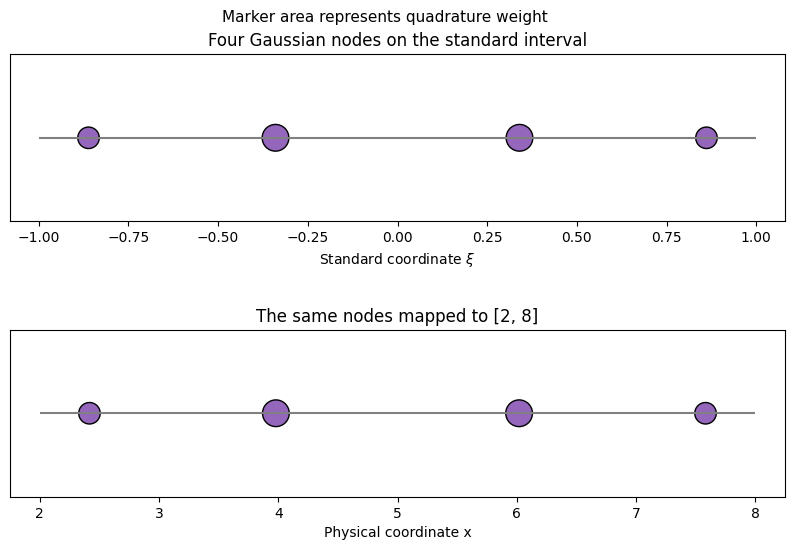

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5.6), sharex=False)

standard_sizes = 90 + 280 * weights_4 / weights_4.max()
physical_sizes = 90 + 280 * physical_weights / physical_weights.max()

axes[0].hlines(0, -1, 1, color="0.5")
axes[0].scatter(
    nodes_4,
    np.zeros_like(nodes_4),
    s=standard_sizes,
    color="tab:purple",
    edgecolor="black",
)
axes[0].set_xlim(-1.08, 1.08)
axes[0].set_yticks([])
axes[0].set_xlabel(r"Standard coordinate $\xi$")
axes[0].set_title("Four Gaussian nodes on the standard interval")

axes[1].hlines(0, lower_demo, upper_demo, color="0.5")
axes[1].scatter(
    physical_nodes,
    np.zeros_like(physical_nodes),
    s=physical_sizes,
    color="tab:purple",
    edgecolor="black",
)
axes[1].set_xlim(lower_demo - 0.25, upper_demo + 0.25)
axes[1].set_yticks([])
axes[1].set_xlabel("Physical coordinate x")
axes[1].set_title("The same nodes mapped to [2, 8]")
fig.suptitle("Marker area represents quadrature weight", fontsize=11)
fig.subplots_adjust(hspace=0.65, top=0.90)
plt.show()


Notice that the nodes do not include the endpoints. Gauss–Legendre quadrature is
an **open** rule in this sense. Endpoint values may still matter physically, but
they are not among this rule's evaluation locations.


## 📂 6.4.6 A transparent manual implementation

The transformed formula can be implemented directly. The function below expects
`integrand` to accept a NumPy array of physical nodes and return an equally shaped
array of function values.


In [ ]:
def gauss_legendre_integrate(integrand, lower, upper, order):
    physical_nodes, physical_weights = gauss_legendre_nodes_weights(
        lower, upper, order
    )
    function_values = np.asarray(integrand(physical_nodes), dtype=float)
    if function_values.shape != physical_nodes.shape:
        raise ValueError("integrand must return one value per node")
    return np.sum(physical_weights * function_values)


exact_exp = np.e - 1.0
manual_exp = gauss_legendre_integrate(np.exp, 0.0, 1.0, order=4)

print(f"Four-point Gaussian estimate: {manual_exp:.12f}")
print(f"Exact integral e - 1:        {exact_exp:.12f}")
print(f"Absolute error:              {abs(exact_exp-manual_exp):.3e}")


Four-point Gaussian estimate: 1.718281827526
Exact integral e - 1:        1.718281828459
Absolute error:              9.330e-10


## 📂 6.4.7 Using `scipy.integrate.fixed_quad`

SciPy provides

```python
value, information = fixed_quad(function, a, b, n=order)
```

where:

* `function` is a callable that must accept vector inputs;
* `a` and `b` are the physical bounds;
* `n` is the number of Gaussian nodes;
* `value` is the quadrature approximation; and
* `information` is currently `None`.

The returned `None` is **not an error estimate**. `fixed_quad` uses the requested
order once and does not adaptively assess convergence.


In [ ]:
scipy_value, scipy_information = fixed_quad(np.exp, 0.0, 1.0, n=4)

scipy_fixed_quad_summary = pd.DataFrame(
    {
        "Calculation": ["Manual transformed rule", "scipy.integrate.fixed_quad", "Exact e - 1"],
        "Value": [manual_exp, scipy_value, exact_exp],
        "Absolute error": [
            abs(exact_exp - manual_exp),
            abs(exact_exp - scipy_value),
            0.0,
        ],
    }
)
display(scipy_fixed_quad_summary)
print("Second fixed_quad return value:", scipy_information)


,Calculation,Value,Absolute error
0,Manual transformed rule,1.7182818275,0.0000000009
1,scipy.integrate.fixed_quad,1.7182818275,0.0000000009
2,Exact e - 1,1.7182818285,0.0000000000


Second fixed_quad return value: None


## 📂 6.4.8 Engineering example: work in a nonlinear spring

Suppose a nonlinear spring has force–displacement relation

$$
F(x)=k_1x+k_3x^3+k_5x^5,
$$

where:

* $x$ is compression in metres;
* $F(x)$ is force in newtons;
* $k_1=1800$ N/m;
* $k_3=1.2\times10^6$ N/m$^3$; and
* $k_5=2.0\times10^8$ N/m$^5$.

The work required to compress the spring from $x=0$ to $x=d$ is

$$
W=\int_0^dF(x)\,\mathrm{d}x.
$$

We use $W$ for physical work in joules. It is not a quadrature weight; individual
quadrature weights retain the lowercase notation $w_i$ or mapped notation $W_i$.


In [ ]:
k1_N_m = 1800.0
k3_N_m3 = 1.2e6
k5_N_m5 = 2.0e8
compression_m = 0.08


def spring_force_N(displacement_m):
    displacement_m = np.asarray(displacement_m, dtype=float)
    return (
        k1_N_m * displacement_m
        + k3_N_m3 * displacement_m**3
        + k5_N_m5 * displacement_m**5
    )


exact_spring_work_J = (
    0.5 * k1_N_m * compression_m**2
    + 0.25 * k3_N_m3 * compression_m**4
    + (1.0 / 6.0) * k5_N_m5 * compression_m**6
)

spring_nodes, spring_weights = gauss_legendre_nodes_weights(0.0, compression_m, order=3)
spring_forces = spring_force_N(spring_nodes)
spring_contributions = spring_weights * spring_forces

spring_table = pd.DataFrame(
    {
        "Node x_i [m]": spring_nodes,
        "Mapped weight W_i [m]": spring_weights,
        "Force F(x_i) [N]": spring_forces,
        "Work contribution [J]": spring_contributions,
    }
)
display(spring_table)
print(f"Three-point Gaussian work: {spring_contributions.sum():.8f} J")
print(f"Analytical work:            {exact_spring_work_J:.8f} J")


,Node x_i [m],Mapped weight W_i [m],Force F(x_i) [N],Work contribution [J]
0,0.0090161332,0.0222222222,17.120468733,0.3804548607
1,0.0400000000,0.0355555556,169.280000000,6.0188444444
2,0.0709838668,0.0222222222,917.407531267,20.3868340282


Three-point Gaussian work: 26.78613333 J
Analytical work:            26.78613333 J


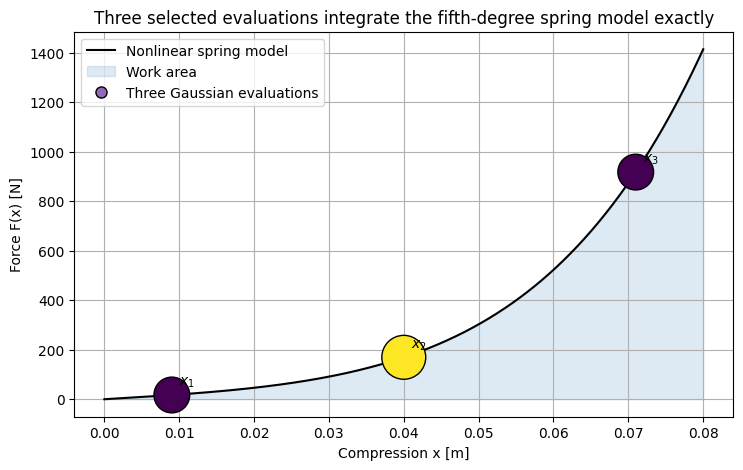

In [ ]:
displacement_dense = np.linspace(0.0, compression_m, 501)
force_dense = spring_force_N(displacement_dense)

fig, ax = plt.subplots()
ax.plot(displacement_dense, force_dense, color="black", label="Nonlinear spring model")
ax.fill_between(displacement_dense, 0.0, force_dense, color="tab:blue", alpha=0.15, label="Work area")
point_sizes = 100 + 900 * spring_weights / spring_weights.max()
ax.scatter(
    spring_nodes,
    spring_forces,
    s=point_sizes,
    c=spring_weights,
    cmap="viridis",
    edgecolor="black",
    zorder=3,
    label="_nolegend_",
)
for index, (node, force) in enumerate(zip(spring_nodes, spring_forces), start=1):
    ax.annotate(f"$x_{index}$", (node, force), xytext=(5, 7), textcoords="offset points")
ax.plot(
    [],
    [],
    "o",
    markersize=8,
    markerfacecolor="tab:purple",
    markeredgecolor="black",
    linestyle="none",
    label="Three Gaussian evaluations",
)
ax.set_xlabel("Compression x [m]")
ax.set_ylabel("Force F(x) [N]")
ax.set_title("Three selected evaluations integrate the fifth-degree spring model exactly")
ax.grid(True)
ax.legend()
plt.show()


The spring force is a fifth-degree polynomial. Three-point Gauss–Legendre
quadrature is exact through degree $2(3)-1=5$, so the numerical work matches the
analytical value apart from floating-point effects.

This is a deliberately favourable verification example. Real constitutive models
may include hysteresis, discontinuities, measured uncertainty or path dependence.


## 📂 6.4.9 Accuracy per function evaluation

When a simulation evaluation is expensive, the number of calls to the integrand
matters. We compare three methods on

$$I=\int_0^1e^x\,\mathrm{d}x=e-1.$$

For a fair count:

* an $n$-point Gaussian rule makes $n$ evaluations;
* an $n$-sample trapezoidal rule makes $n$ evaluations; and
* Simpson results are shown only for odd $n$, where the equal grid contains an
  even number of intervals.


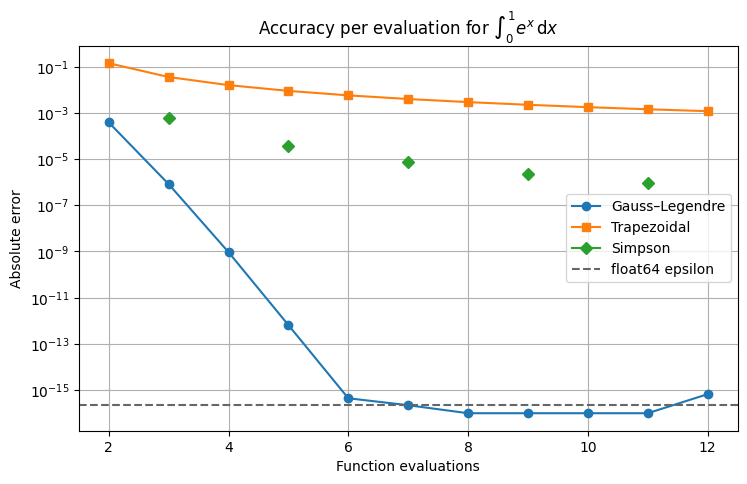

In [ ]:
evaluation_counts = np.arange(2, 13)
efficiency_rows = []

for evaluations in evaluation_counts:
    gaussian_estimate, _ = fixed_quad(np.exp, 0.0, 1.0, n=evaluations)
    equal_nodes = np.linspace(0.0, 1.0, evaluations)
    equal_values = np.exp(equal_nodes)
    simpson_error = np.nan
    if evaluations >= 3 and evaluations % 2 == 1:
        simpson_error = abs(exact_exp - simpson(equal_values, x=equal_nodes))

    efficiency_rows.append(
        {
            "Function evaluations": evaluations,
            "Gaussian error": abs(exact_exp - gaussian_estimate),
            "Trapezoidal error": abs(exact_exp - trapezoid(equal_values, x=equal_nodes)),
            "Simpson error": simpson_error,
        }
    )

efficiency = pd.DataFrame(efficiency_rows)

fig, ax = plt.subplots()
ax.semilogy(
    efficiency["Function evaluations"],
    np.maximum(efficiency["Gaussian error"], 1e-16),
    "o-",
    label="Gauss–Legendre",
)
ax.semilogy(efficiency["Function evaluations"], efficiency["Trapezoidal error"], "s-", label="Trapezoidal")
ax.semilogy(efficiency["Function evaluations"], efficiency["Simpson error"], "D-", label="Simpson")
ax.axhline(np.finfo(float).eps, color="0.4", linestyle="--", label="float64 epsilon")
ax.set_xlabel("Function evaluations")
ax.set_ylabel("Absolute error")
ax.set_title(r"Accuracy per evaluation for $\int_0^1e^x\,\mathrm{d}x$")
ax.grid(True, which="both")
ax.legend()
plt.show()


Gauss–Legendre quadrature is highly efficient for this smooth function. The plot
does not establish that it wins for every problem: method performance depends on
smoothness, singularities, oscillations and where information is available.


## 📂 6.4.10 Engineering return: rocket-motor total impulse

For the synthetic callable thrust model,

$$I_{\mathrm{total}}=\int_0^{10}F(t)\,\mathrm{d}t.$$

Gauss–Legendre quadrature is allowed to request thrust at its selected times. The
exact synthetic-model reference remains available for verification; it is not
physical ground truth.


In [ ]:
def underlying_thrust_N(time_s):
    time_s = np.asarray(time_s, dtype=float)
    burn_duration_s = 10.0
    rise = 1.0 - np.exp(-2.8 * time_s)
    decay = 1.0 - np.exp(-2.2 * (burn_duration_s - time_s))
    modulation = 1.0 + 0.035 * np.sin(1.25 * time_s)
    thrust = 1180.0 * rise * decay * modulation
    return np.where((time_s >= 0.0) & (time_s <= burn_duration_s), thrust, 0.0)


impulse_reference, _ = quad(
    lambda time_s: float(underlying_thrust_N(time_s)),
    0.0,
    10.0,
    epsabs=1e-10,
)

gaussian_orders = np.arange(2, 21)
rocket_gaussian_errors = []
for order in gaussian_orders:
    estimate, _ = fixed_quad(underlying_thrust_N, 0.0, 10.0, n=order)
    rocket_gaussian_errors.append(abs(impulse_reference - estimate))

selected_orders = [3, 5, 8, 12, 16, 20]
selected_rows = []
for order in selected_orders:
    estimate, _ = fixed_quad(underlying_thrust_N, 0.0, 10.0, n=order)
    selected_rows.append(
        {
            "Gaussian order n": order,
            "Impulse estimate [N s]": estimate,
            "Absolute error [N s]": abs(impulse_reference - estimate),
        }
    )
display(pd.DataFrame(selected_rows))


,Gaussian order n,Impulse estimate [N s],Absolute error [N s]
0,3,11383.2688621609,5.3749218588e+02
1,5,10907.2453462238,6.1468669946e+01
2,8,10846.1098393386,3.3316306112e-01
3,12,10845.7767115452,3.5267770727e-05
4,16,10845.7766762776,1.2732925825e-10
5,20,10845.7766762774,1.0913936421e-11


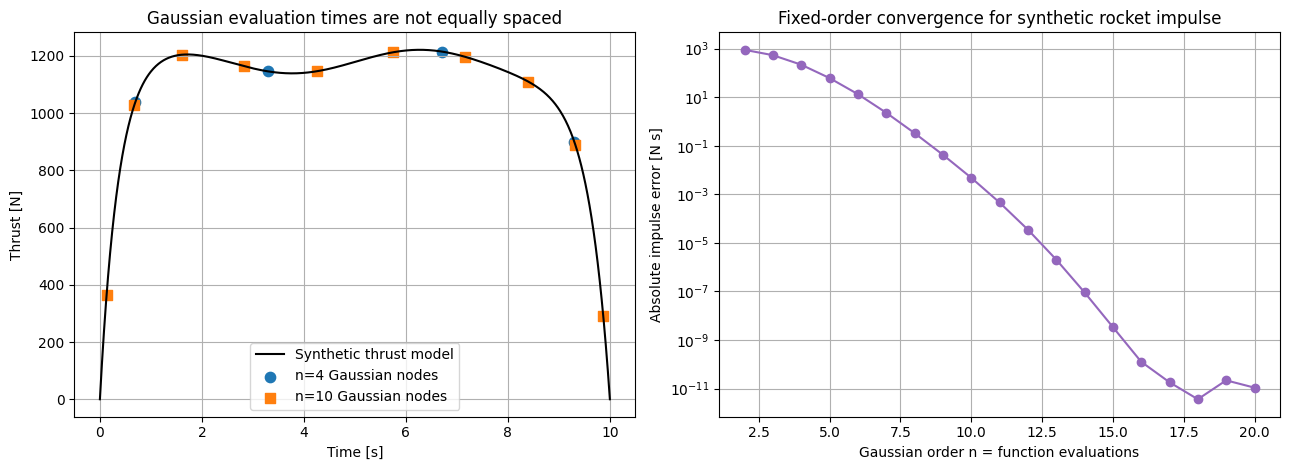

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

time_dense = np.linspace(0.0, 10.0, 1001)
axes[0].plot(time_dense, underlying_thrust_N(time_dense), color="black", label="Synthetic thrust model")
for order, marker in [(4, "o"), (10, "s")]:
    nodes, _ = gauss_legendre_nodes_weights(0.0, 10.0, order)
    axes[0].scatter(
        nodes,
        underlying_thrust_N(nodes),
        marker=marker,
        s=55,
        label=f"n={order} Gaussian nodes",
    )
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Thrust [N]")
axes[0].set_title("Gaussian evaluation times are not equally spaced")
axes[0].grid(True)
axes[0].legend()

axes[1].semilogy(gaussian_orders, rocket_gaussian_errors, "o-", color="tab:purple")
axes[1].set_xlabel("Gaussian order n = function evaluations")
axes[1].set_ylabel("Absolute impulse error [N s]")
axes[1].set_title("Fixed-order convergence for synthetic rocket impulse")
axes[1].grid(True, which="both")

plt.tight_layout()
plt.show()


The nodes cluster somewhat toward the bounds but do not include them. Increasing
$n$ generally improves the synthetic impulse estimate as the rule represents more
of the start-up, modulation and shut-down behaviour. Once errors reach roughly
floating-point precision, the curve can flatten or move slightly upward; more
nodes do not provide unlimited numerical accuracy.

Comparing orders $n$ and $n+1$ can show sensitivity to quadrature order. Their
difference is not automatically the true error when $I$ is unknown.


## 📂 6.4.11 Existing sensor samples are a different problem

Gaussian quadrature chooses its evaluation nodes. Suppose a thrust test has
already recorded equally spaced measurements. Those times generally do not match
the Gaussian nodes.

Calling the generating model at Gaussian nodes is valid in our synthetic example.
Looking up values that were never measured is not possible in a completed real
experiment. Interpolating the sensor data onto Gaussian nodes creates a new model
and introduces interpolation assumptions; it does not create new information.


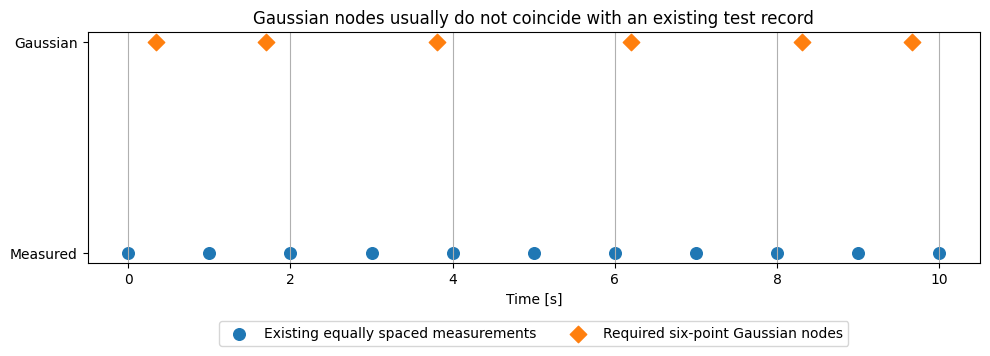

In [ ]:
measured_times = np.linspace(0.0, 10.0, 11)
gaussian_times, _ = gauss_legendre_nodes_weights(0.0, 10.0, order=6)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.scatter(measured_times, np.zeros_like(measured_times), s=70, label="Existing equally spaced measurements")
ax.scatter(gaussian_times, np.ones_like(gaussian_times), marker="D", s=70, label="Required six-point Gaussian nodes")
ax.set_yticks([0, 1], ["Measured", "Gaussian"])
ax.set_xlabel("Time [s]")
ax.set_title("Gaussian nodes usually do not coincide with an existing test record")
ax.grid(True, axis="x")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
plt.tight_layout()
plt.show()


For existing sampled measurements, `trapezoid(y, x=x)` or `simpson(y, x=x)` may
better respect the data actually collected. Gaussian quadrature becomes attractive
when the experiment, simulation or surrogate can be queried at its required nodes.


## 📂 6.4.12 Composite Gauss–Legendre quadrature

One global Gaussian panel may struggle when behaviour is concentrated in a small
part of a long interval. A composite approach divides $[a,b]$ into subintervals
and applies the same low-order Gaussian rule within each panel.

If panel boundaries are

$$a=x_0<x_1<\cdots<x_m=b,$$

then

$$
I\approx \sum_{j=0}^{m-1}G_n^{(j)},
$$

where $G_n^{(j)}$ is an $n$-point Gaussian approximation on panel
$[x_j,x_{j+1}]$. Here $j$ indexes panels, while $n$ remains the Gaussian order
inside each panel.


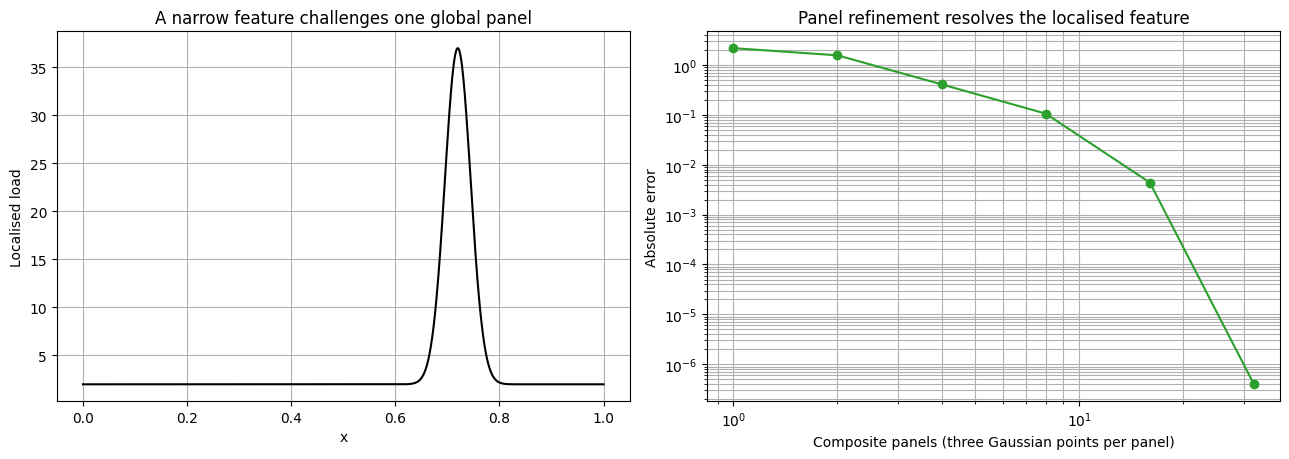

In [ ]:
def composite_fixed_gauss(integrand, lower, upper, order, panels):
    if panels < 1:
        raise ValueError("panels must be at least 1")
    boundaries = np.linspace(lower, upper, panels + 1)
    total = 0.0
    for left, right in zip(boundaries[:-1], boundaries[1:]):
        panel_value, _ = fixed_quad(integrand, left, right, n=order)
        total += panel_value
    return total


def localised_load(x):
    x = np.asarray(x, dtype=float)
    return 2.0 + 35.0 * np.exp(-((x - 0.72) / 0.035) ** 2)


localised_reference, _ = quad(
    lambda x: float(localised_load(x)), 0.0, 1.0, epsabs=1e-12
)

panel_counts = np.array([1, 2, 4, 8, 16, 32])
composite_errors = []
for panels in panel_counts:
    estimate = composite_fixed_gauss(localised_load, 0.0, 1.0, order=3, panels=panels)
    composite_errors.append(abs(localised_reference - estimate))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
x_local = np.linspace(0.0, 1.0, 1201)
axes[0].plot(x_local, localised_load(x_local), color="black")
axes[0].set_xlabel("x")
axes[0].set_ylabel("Localised load")
axes[0].set_title("A narrow feature challenges one global panel")
axes[0].grid(True)

axes[1].loglog(panel_counts, composite_errors, "o-", color="tab:green")
axes[1].set_xlabel("Composite panels (three Gaussian points per panel)")
axes[1].set_ylabel("Absolute error")
axes[1].set_title("Panel refinement resolves the localised feature")
axes[1].grid(True, which="both")

plt.tight_layout()
plt.show()


Composite panels increase the total evaluation count to $mn$, where $m$ is the
number of panels and $n$ is the Gaussian order per panel. Panel boundaries should
reflect known features where possible. Blindly adding panels cannot recover
unmodelled physics or faulty measurements.


## 📂 6.4.13 When smoothness is lost

Gaussian polynomial exactness is most powerful for smooth integrands. Corners,
discontinuities, singularities and unresolved oscillations can reduce the
advantage. If a known corner lies inside the interval, splitting the integral at
that coordinate may be more effective than increasing one global order.

As in 6.2 and 6.3, a high-order method cannot repair sensor bias, incorrect units,
wrong bounds or a feature absent from the available information.


## 📂 6.4.14 Optional interactive Gaussian nodes

Move the slider to change the Gaussian order on the nonlinear spring model. The
title reports the work error, while marker size represents the mapped quadrature
weight. The displayed locations are function evaluations, not ordinary equally
spaced sensor samples.


In [ ]:
def plot_spring_gaussian_order(order=3):
    nodes, weights = gauss_legendre_nodes_weights(0.0, compression_m, order)
    forces = spring_force_N(nodes)
    estimate = np.sum(weights * forces)

    fig, ax = plt.subplots()
    ax.plot(displacement_dense, force_dense, color="black", label="Spring model")
    marker_sizes = 80 + 700 * weights / weights.max()
    ax.scatter(
        nodes,
        forces,
        s=marker_sizes,
        c=weights,
        cmap="viridis",
        edgecolor="black",
        zorder=3,
        label=f"{order} Gaussian nodes",
    )
    ax.set_xlabel("Compression x [m]")
    ax.set_ylabel("Force F(x) [N]")
    ax.set_title(
        f"Order n={order}: work={estimate:.8f} J, "
        f"absolute error={abs(exact_spring_work_J-estimate):.2e} J"
    )
    ax.grid(True)
    ax.legend()
    plt.show()


try:
    import ipywidgets as widgets

    widgets.interact(
        plot_spring_gaussian_order,
        order=widgets.IntSlider(
            value=3,
            min=1,
            max=8,
            step=1,
            description="Order n",
            continuous_update=False,
        ),
    )
except ImportError:
    print("ipywidgets is unavailable; showing the three-point case.")
    plot_spring_gaussian_order(order=3)


interactive(children=(IntSlider(value=3, continuous_update=False, description='Order n', max=8, min=1), Output…

## 📂 6.4.15 Method selection

| Situation | Gauss–Legendre suitability | Reason |
|---|---|---|
| Smooth callable model on a finite interval | Strong | selected nodes provide high polynomial exactness |
| Expensive simulation callable at chosen points | Often strong | high accuracy per evaluation can reduce cost |
| Existing irregular sensor record | Usually poor directly | required Gaussian-node values are unavailable |
| Known localised feature | Consider composite panels | subintervals can resolve the feature |
| Corner or discontinuity | Split at the feature when possible | one smooth polynomial approximation is inappropriate across it |
| Singular or infinite-interval problem | Requires another formulation or Gaussian family | standard Gauss–Legendre assumptions do not match |
| No accumulation in the engineering question | Not relevant | choose analysis based on the required output |

Other Gaussian families use different intervals and weighting functions. For
example, Gauss–Hermite and Gauss–Laguerre rules target different mathematical
structures. Selecting them requires recognising that structure; they are not
interchangeable names for a higher-order setting.


## 📂 6.4.16 Common interpretation failures

| Failure | Why it is unsafe | Better action |
|---|---|---|
| Treating $G_n$ as a renamed $I$ | approximation and ideal value have different roles | write $G_n\approx I$ and validate |
| Forgetting the interval scale factor | weights still represent $[-1,1]$ | map both nodes and weights |
| Calling `None` from `fixed_quad` an error estimate | SciPy does not return one here | compare justified orders or an independent reference |
| Using existing samples as if they were Gaussian nodes | the coordinates do not match | preserve the real coordinates or redesign sampling |
| Interpolating and claiming new measurements | interpolation adds assumptions, not information | disclose and validate the interpolation model |
| Assuming degree $2n-1$ means every function is exact | the guarantee applies to polynomials | test convergence for the actual integrand |
| Raising $n$ without checking features | non-smooth or localised behaviour may dominate | inspect the function and consider panel splitting |


## 📂 6.4.17 Useful packages and functions

| Package | Function or technique | Purpose | Important caution |
|---|---|---|---|
| NumPy | `polynomial.legendre.leggauss` | return standard Gauss–Legendre nodes and weights | nodes are on $[-1,1]$ |
| SciPy | `integrate.fixed_quad` | fixed-order Gaussian integration of a callable | callable must accept vector inputs; no error estimate is returned |
| SciPy | `special.eval_legendre` | evaluate a Legendre polynomial | mainly used here to visualise node roots |
| SciPy | `integrate.quad` | generate a synthetic-model reference | numerical error estimate is not measurement uncertainty |
| NumPy | weighted sum | implement transformed Gaussian rules | check array shapes, bounds and units |
| Matplotlib | `scatter`, colour and marker size | visualise nodes and weights | appearance is not accuracy evidence |


## 📂 6.4.18 Engineering workflow and summary

A defensible Gauss–Legendre workflow is:

1. confirm that an accumulated quantity answers the engineering question;
2. confirm that the integrand is callable at selected coordinates;
3. inspect smoothness, localised behaviour, bounds and units;
4. choose a Gaussian order $n$ and obtain standard nodes $\xi_i$ and weights $w_i$;
5. map both nodes and weights to the physical interval $[a,b]$;
6. evaluate the model at the mapped nodes and form the weighted sum $G_n$;
7. compare justified orders or composite panels to assess sensitivity;
8. verify the implementation on a known integral;
9. assess modelling and measurement uncertainty separately; and
10. report the order, evaluations, bounds, convergence evidence and limitations.

**Key result:** an $n$-point Gauss–Legendre rule is exact for polynomials through
degree $2n-1$. Its efficiency comes from selecting nodes and weights together.
This advantage applies when those selected evaluations are actually available and
the integrand is sufficiently well behaved.


## 📚 References

* NIST Digital Library of Mathematical Functions, *Gauss Quadrature*, Section 3.5(v).
* SciPy developers, *`scipy.integrate.fixed_quad`*, stable documentation.
* NumPy developers, *`numpy.polynomial.legendre.leggauss`*, stable documentation.
* SciPy developers, *`scipy.special.roots_legendre`*, stable documentation.

## 🤖 AI Acknowledgment

Generative AI was used to help structure explanations, develop deterministic
teaching examples and review code. The teaching team remains responsible for the
mathematics, engineering interpretation, source selection and final notebook.
